In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dropout, Dense, Flatten, Conv2D, MaxPool2D, BatchNormalization
# layers for data augmentation
from tensorflow.keras.layers import RandomZoom, RandomTranslation, RandomBrightness, RandomRotation

from matplotlib import pyplot as plt

import pandas as pd
import numpy as np

I0000 00:00:1793702813.236423     893 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## loading the Sign-Language MNIST hand gestures dataset
![MNIST sign-language gestures](mnist_american_sign_language.png "MNIST sign-language gestures")

In [2]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']

X_train = train.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
y_train = train.iloc[:, 0].to_numpy()
X_test = test.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
y_test = test.iloc[:, 0].to_numpy()

## shapes of train and test data

In [3]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print()
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27455, 28, 28)
y_train: (27455,)

X_test: (7172, 28, 28)
y_test: (7172,)


## show the first 12 training hand gestures

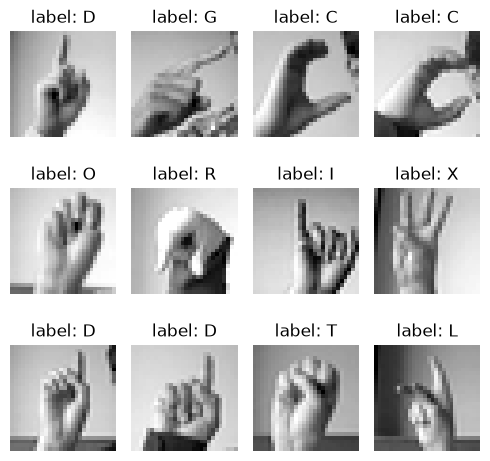

In [4]:
plt.figure(figsize=(5,5))
for k in range(12):
    subplt = plt.subplot(3, 4, k+1)
    subplt.set_title(f"label: {labels[y_train[k]]}")
    plt.imshow(X_train[k], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

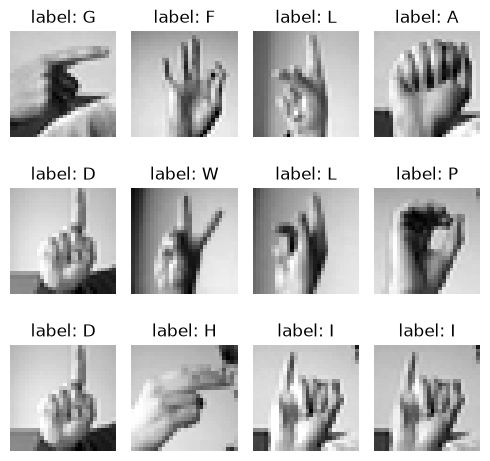

In [5]:
# show the first 12 test hand gestures

plt.figure(figsize=(5,5))
for k in range(12):
    subplt = plt.subplot(3, 4, k+1)
    subplt.set_title(f"label: {labels[y_test[k]]}")
    plt.imshow(X_test[k], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

## adjust the traning and testing input

In [6]:
X_train = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255
X_test = X_test.reshape(-1, 28, 28, 1).astype('float32') / 255

from sklearn.preprocessing import LabelBinarizer
label_binarizer = LabelBinarizer()
y_train = label_binarizer.fit_transform(y_train)
y_test = label_binarizer.fit_transform(y_test)

## data augmentation and preparing for training

In [7]:
datagen = Sequential([
    RandomRotation(
        factor=10/360,
        fill_mode="nearest"
    ),
    RandomZoom(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),
    RandomBrightness(
        factor=0.1,
        value_range=(0, 1)
    ),
], name="data_augmentation")

train_dataset = (
    tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(1024)
        .batch(128)
        .map(
            lambda x, y: (datagen(x, training=True), y),
            num_parallel_calls=(tf.data.AUTOTUNE)
        )
)

I0000 00:00:1793702885.026114     893 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


## building the model

In [8]:
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(75 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Conv2D(50 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Conv2D(25 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Flatten())
model.add(Dense(units = 512 , activation = 'relu'))
model.add(Dropout(0.3))
model.add(Dense(units = 24 , activation = 'softmax'))
model.compile(optimizer = 'adam' , loss = 'categorical_crossentropy' , metrics = ['accuracy'])

## visualization of trainable CNN

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 75)     │           750 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 75)     │           300 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 75)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 50)     │        33,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 50)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 50)     │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 50)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 25)       │        11,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 25)       │           100 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 25)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       205,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │        12,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,049 (1.01 MB)

 Trainable params: 263,749 (1.01 MB)

 Non-trainable params: 300 (1.17 KB)

/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/visualkeras/layered.py:231: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


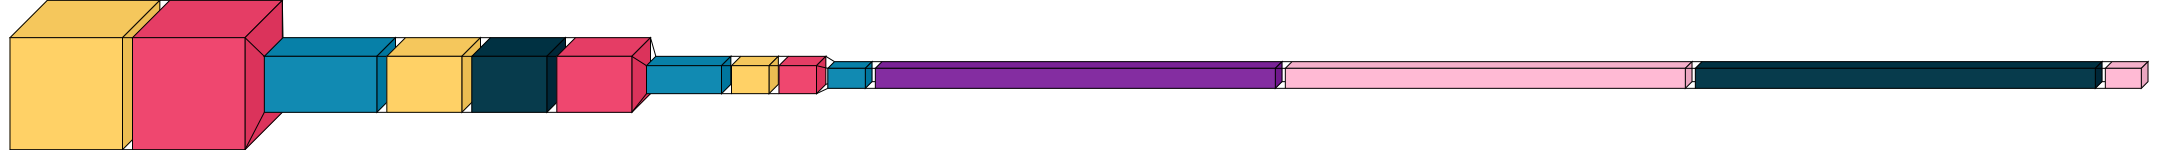

In [10]:
import visualkeras

for layer in model.layers:
    if not hasattr(layer, 'output_shape'):
        layer.output_shape = layer.output.shape
        
visualkeras.layered_view(model).show()

## training the model

In [11]:
history = model.fit(train_dataset, epochs=20, validation_data=(X_test, y_test))

Epoch 1/20


/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793702890.331929    1303 service.cc:154] XLA service 0x7dc59c51e0e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793702890.331976    1303 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce GTX 1660 SUPER, Compute Capability 7.5 (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793702890.452499    1303 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793702891.836137    1391 cuda_dnn.cc:442] Loaded cuDNN version 92700


 13/215 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1190 - loss: 3.2603

I0000 00:00:1793702895.868984    1303 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


215/215 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.6316 - loss: 1.1880 - val_accuracy: 0.1711 - val_loss: 3.5595
Epoch 2/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9182 - loss: 0.2476 - val_accuracy: 0.5512 - val_loss: 1.4319
Epoch 3/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9611 - loss: 0.1213 - val_accuracy: 0.9650 - val_loss: 0.1073
Epoch 4/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9785 - loss: 0.0668 - val_accuracy: 0.9916 - val_loss: 0.0305
Epoch 5/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9832 - loss: 0.0525 - val_accuracy: 0.9978 - val_loss: 0.0182
Epoch 6/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9859 - loss: 0.0423 - val_accuracy: 0.9300 - val_loss: 0.2052
Epoch 7/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9876 - loss: 0.0377 - val_accuracy: 0.9876 - val_loss: 0.0327
Epoch 8/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9886 - loss: 0.0352 - val_accuracy: 0.97

## analysis after model training

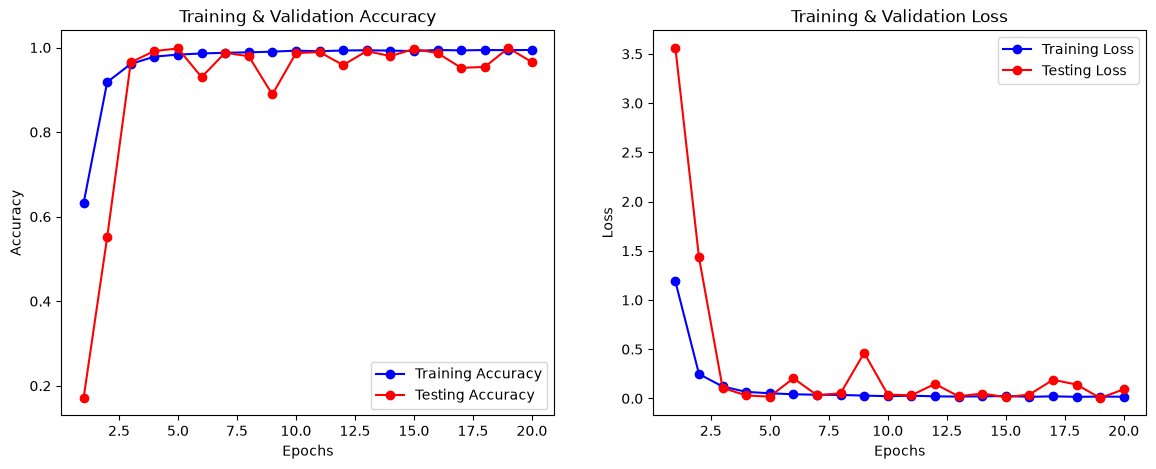

In [12]:
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

epochs = range(1, len(train_loss) + 1)

fig , ax = plt.subplots(1,2)
fig.set_size_inches(14,5)

ax[0].plot(epochs , train_acc , 'bo-' , label = 'Training Accuracy')
ax[0].plot(epochs , val_acc , 'ro-' , label = 'Testing Accuracy')
ax[0].set_title('Training & Validation Accuracy')
ax[0].legend()
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("Accuracy")

ax[1].plot(epochs , train_loss , 'bo-' , label = 'Training Loss')
ax[1].plot(epochs , val_loss , 'ro-' , label = 'Testing Loss')
ax[1].set_title('Training & Validation Loss')
ax[1].legend()
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("Loss")
plt.show()

## converting model to tflite format

In [13]:
# choice some images from training dataset for calibration
rng = np.random.default_rng(42)
indices = rng.choice(
    len(X_train),
    size=min(300, len(X_train)),
    replace=False
)
def representative_dataset():
    for idx in indices:
        image = X_train[idx:idx+1].astype(np.float32)
        yield [image]


# creating convertor
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# optimizing model
converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

# calibration
converter.representative_dataset = representative_dataset

# integer model quantization (int8)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# convertation
tflite_model = converter.convert()

# saving model as .tflite
with open("hand_gesture_model_int8.tflite", "wb") as f:
    f.write(tflite_model)

print("model converted successfully")
print("size KB:", len(tflite_model) / 1024)


INFO:tensorflow:Assets written to: /tmp/tmpecloelzy/assets


INFO:tensorflow:Assets written to: /tmp/tmpecloelzy/assets


Saved artifact at '/tmp/tmpecloelzy'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 24), dtype=tf.float32, name=None)
Captures:
  138292916371776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138292916372016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293055059392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293055050752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293055057232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293055059632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293055054592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293055054352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293045597184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138293045595024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1382930455974

/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793702961.108767     893 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793702961.108810     893 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793702961.109156     893 reader.cc:83] Reading SavedModel from: /tmp/tmpecloelzy
I0000 00:00:1793702961.109795     893 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793702961.109802     893 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpecloelzy
I0000 00:00:1793702961.120497     893 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793702961.122158     893 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793702961.168451     893 loader.cc:221] Running init

model converted successfully
size KB: 283.546875


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1793702961.944720     893 flatbuffer_export.cc:4171] Skipping runtime version metadata in the model. This will be generated by the exporter.
